<a href="https://colab.research.google.com/github/smruthi215/DLG--LAB/blob/main/lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

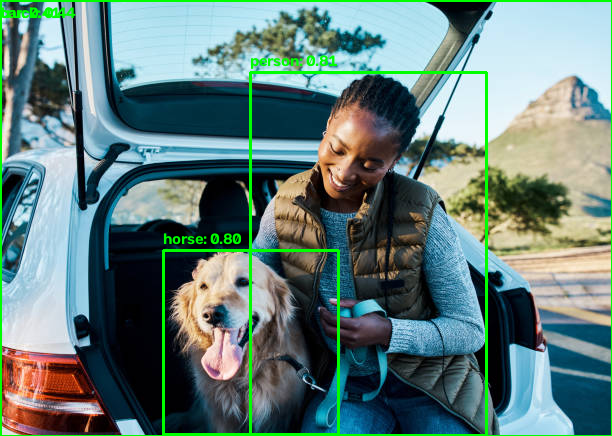

In [ ]:
import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
import os
from google.colab.patches import cv2_imshow

# 1. Load a pre-trained object detection model from TensorFlow Hub
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"
detector = hub.load(MODEL_URL)

# COCO labels list
COCO_CLASSES = [
    'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat',
    'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat',
    'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack',
    'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
    'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
    'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple',
    'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake',
    'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop',
    'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
    'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]

def detect_objects_with_boxes(img_path, model):
    orig_image = cv2.imread(img_path)
    if orig_image is None:
        raise FileNotFoundError(f"Image not found at {img_path}")

    # Convert image to tensor
    image_tensor = tf.convert_to_tensor(orig_image, dtype=tf.uint8)
    image_tensor = tf.expand_dims(image_tensor, axis=0)

    # Run detection
    results = model(image_tensor)

    # Extract results
    boxes = results['detection_boxes'][0].numpy()
    classes = results['detection_classes'][0].numpy().astype(int)
    scores = results['detection_scores'][0].numpy()

    h, w, _ = orig_image.shape

    for i in range(len(scores)):
        if scores[i] > 0.4:  # Threshold limit
            ymin, xmin, ymax, xmax = boxes[i]
            (left, right, top, bottom) = (int(xmin * w), int(xmax * w), int(ymin * h), int(ymax * h))

            # Draw bounding box
            cv2.rectangle(orig_image, (left, top), (right, bottom), (0, 255, 0), 2)

            # Put class name and confidence score
            class_id = classes[i] - 1
            class_name = COCO_CLASSES[class_id] if 0 <= class_id < len(COCO_CLASSES) else "unknown"
            label = f"{class_name}: {scores[i]:.2f}"
            cv2.putText(orig_image, label, (left, max(18, top - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    return orig_image

# Pointing to your selected image
image_path = "/content/example1.jpg"

# Detect objects and draw bounding boxes
result_image = detect_objects_with_boxes(image_path, detector)

# Display output inside Colab
cv2_imshow(result_image)

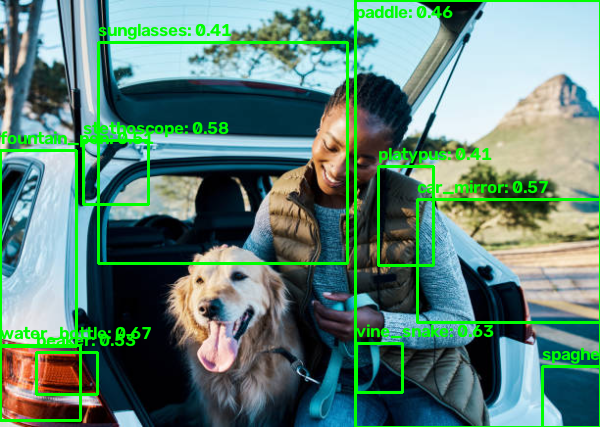

In [ ]:
# 0. SETUP (run once) install OpenCV with Selective Search, then auto-restart.
# After the runtime reconnects, run all cells again from the top.
import os
import subprocess

try:
  import cv2

  ss_ready = hasattr(cv2, "ximgproc") and hasattr(
      cv2.ximgproc, "segmentation"
  )
except Exception:
  ss_ready = False

if not ss_ready:
  subprocess.run(
      "pip uninstall -y -q opencv-python opencv-python-headless"
      " opencv-contrib-python opencv-contrib-python-headless",
      shell=True,
  )
  subprocess.run("pip install -q opencv-contrib-python", shell=True)
  os.kill(os.getpid(), 9)  # restart runtime once then run all cells again

# 1. IMPORTS
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import (
    decode_predictions,
    preprocess_input,
)

# 2. CLASSIFIER: VGG16 pre-trained on ImageNet (knows 1000 objects; no training)
# include_top=True keeps VGG16's 1000-class head, so it can NAME each region directly.
model = VGG16(weights="imagenet", include_top=True)


# 3. REGION PROPOSALS: Selective Search (Fast), with a safe fallback
def get_region_proposals(img, max_regions=200):
  try:
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(img)
    ss.switchToSelectiveSearchFast()  # Fast mode
    boxes = [
        (x, y, w, h) for (x, y, w, h) in ss.process() if w > 40 and h > 40
    ]
    if boxes:
      return boxes[:max_regions]
  except Exception:
    pass

  # fallback: multi-scale sliding windows (always works)
  H, W = img.shape[:2]
  boxes = []
  for s in (0.6, 0.4, 0.25):
    bw, bh = int(W * s), int(H * s)
    for y in range(0, H - bh + 1, max(1, bh // 2)):
      for x in range(0, W - bw + 1, max(1, bw // 2)):
        boxes.append((x, y, bw, bh))
  return boxes[:max_regions]


# 4. NON-MAXIMUM SUPPRESSION: drop duplicate overlapping boxes
def non_max_suppression(dets, iou_thr=0.3):
  if not dets:
    return []
  boxes = np.array(
      [[x, y, x + w, y + h] for (x, y, w, h), _, _ in dets], dtype=float
  )
  scores = np.array([s for _, _, s in dets])

  order = scores.argsort()[::-1]
  keep = []

  while len(order) > 0:
    i = order[0]
    keep.append(i)
    rest = order[1:]

    xx1 = np.maximum(boxes[i, 0], boxes[rest, 0])
    yy1 = np.maximum(boxes[i, 1], boxes[rest, 1])
    xx2 = np.minimum(boxes[i, 2], boxes[rest, 2])
    yy2 = np.minimum(boxes[i, 3], boxes[rest, 3])

    w = np.clip(xx2 - xx1, 0, None)
    h = np.clip(yy2 - yy1, 0, None)
    inter = w * h

    area_i = (boxes[i, 2] - boxes[i, 0]) * (boxes[i, 3] - boxes[i, 1])
    area_r = (boxes[rest, 2] - boxes[rest, 0]) * (
        boxes[rest, 3] - boxes[rest, 1]
    )

    order = rest[(inter / (area_i + area_r - inter + 1e-9)) < iou_thr]

  return [dets[i] for i in keep]


# 5. RUN IT: Using your specified image file path directly
image_path = "/content/example1.jpg"

img = cv2.imread(image_path)
if img is None:
  raise FileNotFoundError(f"Please make sure {image_path} exists.")

H0, W0 = img.shape[:2]
img = cv2.resize(img, (600, int(H0 * 600.0 / W0)))  # downscale faster

boxes = get_region_proposals(img, max_regions=200)
crops = np.array(
    [
        cv2.resize(img[y : y + h, x : x + w], (224, 224))
        for (x, y, w, h) in boxes
    ],
    dtype=np.float32,
)
preds = model.predict(
    preprocess_input(crops), batch_size=32, verbose=0
)  # one batched call

detections = []
for (x, y, w, h), p in zip(boxes, preds):
  _, label, prob = decode_predictions(p[None], top=1)[0][0]
  if prob > 0.40:  # Adjusted confidence threshold to show candidate detections on your image
    detections.append(((x, y, w, h), label, float(prob)))

detections = non_max_suppression(detections, iou_thr=0.3)

for (x, y, w, h), label, score in detections:
  cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
  cv2.putText(
      img,
      f"{label}: {score:.2f}",
      (x, max(18, y - 6)),
      cv2.FONT_HERSHEY_SIMPLEX,
      0.6,
      (0, 255, 0),
      2,
  )

cv2_imshow(img)  # show in Colab